In [47]:
import os
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import textwrap

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

In [48]:
csv_files = glob.glob('strategy_two_results/results_*.csv')

df_list = [pd.read_csv(file) for file in csv_files]
df = pd.concat(df_list, ignore_index=True)

print(f"Combined dataframe shape: {df.shape}")

df.columns

Combined dataframe shape: (1728, 14)


Index(['id', 'timestamp', 'model', 'temperature', 'capacity_context', 'pair',
       'option_1', 'option_2', 'selected_choice', 'response_text',
       'infection_rate_selected', 'npi_level_selected',
       'infection_rate_non_selected', 'npi_level_non_selected'],
      dtype='object')

In [49]:
# Create is_bad_choice column
# A bad choice is either:
# 1. Selecting higher infection rate with same or stricter NPI
# 2. Selecting stricter NPI with same or lower infection rate
df['is_bad_choice'] = (
    ((df['infection_rate_selected'] > df['infection_rate_non_selected']) & 
     (df['npi_level_selected'] >= df['npi_level_non_selected'])) |
    ((df['npi_level_selected'] > df['npi_level_non_selected']) & 
    (df['infection_rate_selected'] <= df['infection_rate_non_selected']))
)

df['is_bad_choice'].value_counts()

is_bad_choice
False    1073
True      655
Name: count, dtype: int64

In [50]:
# Extract second letter from pair column (e.g., "A-B" -> "B")
df['second_option_letter'] = df['pair'].str.split('-').str[1]

# Check if selected choice matches second option
df['is_second_choice'] = df['selected_choice'] == df['second_option_letter']

# Check the distribution
print(df['is_second_choice'].value_counts())
print(f"\nPercentage selecting second option: {df['is_second_choice'].mean() * 100:.2f}%")

is_second_choice
False    995
True     733
Name: count, dtype: int64

Percentage selecting second option: 42.42%


In [51]:
df['infection_preference'] = (df['infection_rate_selected'] - df['infection_rate_non_selected'])
df['npi_preference'] = (df['npi_level_selected'] - df['npi_level_non_selected'])

In [52]:
df['is_valid_choice'] = df['selected_choice'].isin(df['pair'].str.split('-').explode())

In [53]:
df['is_valid_choice'].value_counts()

is_valid_choice
True    1728
Name: count, dtype: int64

In [54]:
def generate_errorbar_plot(response_col, df, context_cols=None, use_percentage=False):
    import textwrap
    from scipy import stats
    
    # Set publication-quality settings
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 300
    sns.set_theme(style='whitegrid')
    
    # Configuration
    MAX_LABEL_LENGTH = 30  # Characters per line
    if context_cols is None:
        context_cols = ['model']
    
    # Set unit label based on percentage flag
    unit = '%' if use_percentage else ''
    
    # Calculate overall mean for reference line
    overall_mean = df[response_col].mean()
    if use_percentage:
        overall_mean = overall_mean * 100
    
    # Wrap labels to multiple lines
    def wrap_label(text, max_len=MAX_LABEL_LENGTH):
        """Wrap text to multiple lines"""
        text = str(text)
        return '\n'.join(textwrap.wrap(text, width=max_len))
    
    # Create separate plot for each context
    for col in context_cols:
        grouped = df.groupby(col)[response_col]
        
        # Calculate means and 95% CI for each group
        means = []
        ci_lower = []
        ci_upper = []
        labels = []
        group_names = []
        
        for name, group in grouped:
            if len(group) > 0:
                # Get data
                data = group.values
                if use_percentage:
                    data = data * 100
                
                # Calculate mean
                mean_val = data.mean()
                means.append(mean_val)
                group_names.append(name)
                
                # Calculate 95% CI using scipy
                ci = stats.t.interval(0.95, len(data)-1, 
                                     loc=mean_val, 
                                     scale=stats.sem(data))
                ci_lower.append(mean_val - ci[0])
                ci_upper.append(ci[1] - mean_val)
                labels.append(wrap_label(str(name)))
        
        # Sort by mean values (descending)
        sorted_indices = sorted(range(len(means)), key=lambda i: means[i], reverse=True)
        means = [means[i] for i in sorted_indices]
        ci_lower = [ci_lower[i] for i in sorted_indices]
        ci_upper = [ci_upper[i] for i in sorted_indices]
        labels = [labels[i] for i in sorted_indices]
        
        # Adjust figure height based on number of items
        fig_height = max(6, len(labels) * 0.6)
        fig, ax = plt.subplots(figsize=(12, fig_height))
        
        # Create horizontal error bar plot
        y_positions = range(1, len(labels) + 1)
        ax.errorbar(means, y_positions,
                   xerr=[ci_lower, ci_upper],
                   fmt='o',  # Circle marker
                   markersize=12,
                   markerfacecolor='#e36a6a',
                   markeredgecolor='black',
                   markeredgewidth=1.5,
                   ecolor='black',
                   elinewidth=2,
                   capsize=6,
                   capthick=2)
        
        # Vertical mean line
        ax.axvline(overall_mean, color='red', linestyle='--', linewidth=2.5, alpha=0.7,
                  label=f'Overall mean = {overall_mean:.2f}{unit}')
        
        # Labels with wrapping and increased font size
        ax.set_yticks(y_positions)
        ax.set_yticklabels(labels, fontsize=18)
        
        xlabel = f'{response_col} (Mean with 95% CI)'
        if use_percentage:
            xlabel = f'{response_col} (% Mean with 95% CI)'
        ax.set_xlabel(xlabel, fontsize=18, fontweight='bold')
        ax.set_title(f'Strategy One: {response_col} by {col}', fontsize=18, fontweight='bold', pad=20)
        
        # Grid for easier reading
        ax.grid(True, axis='x', alpha=0.3, linewidth=1.2)
        ax.set_axisbelow(True)
        
        ax.legend(fontsize=18, loc='best')
        
        # Increase tick label size
        ax.tick_params(axis='x', labelsize=18)
        ax.tick_params(axis='y', labelsize=18)
        
        # Set y-axis limits with padding
        ax.set_ylim(0.5, len(labels) + 0.5)
        
        plt.tight_layout()
        plt.show()
    
    print(f"\nLabels wrapped at {MAX_LABEL_LENGTH} characters per line")
    print(f"Overall mean {response_col}: {overall_mean:.2f}{unit}")

# Example usage:
# For raw values (like infection_rate_selected):
# generate_errorbar_plot('infection_rate_selected', df=df)
# For percentage values (like is_bad_choice which is 0/1):
# generate_errorbar_plot('is_bad_choice', df=df, use_percentage=True)

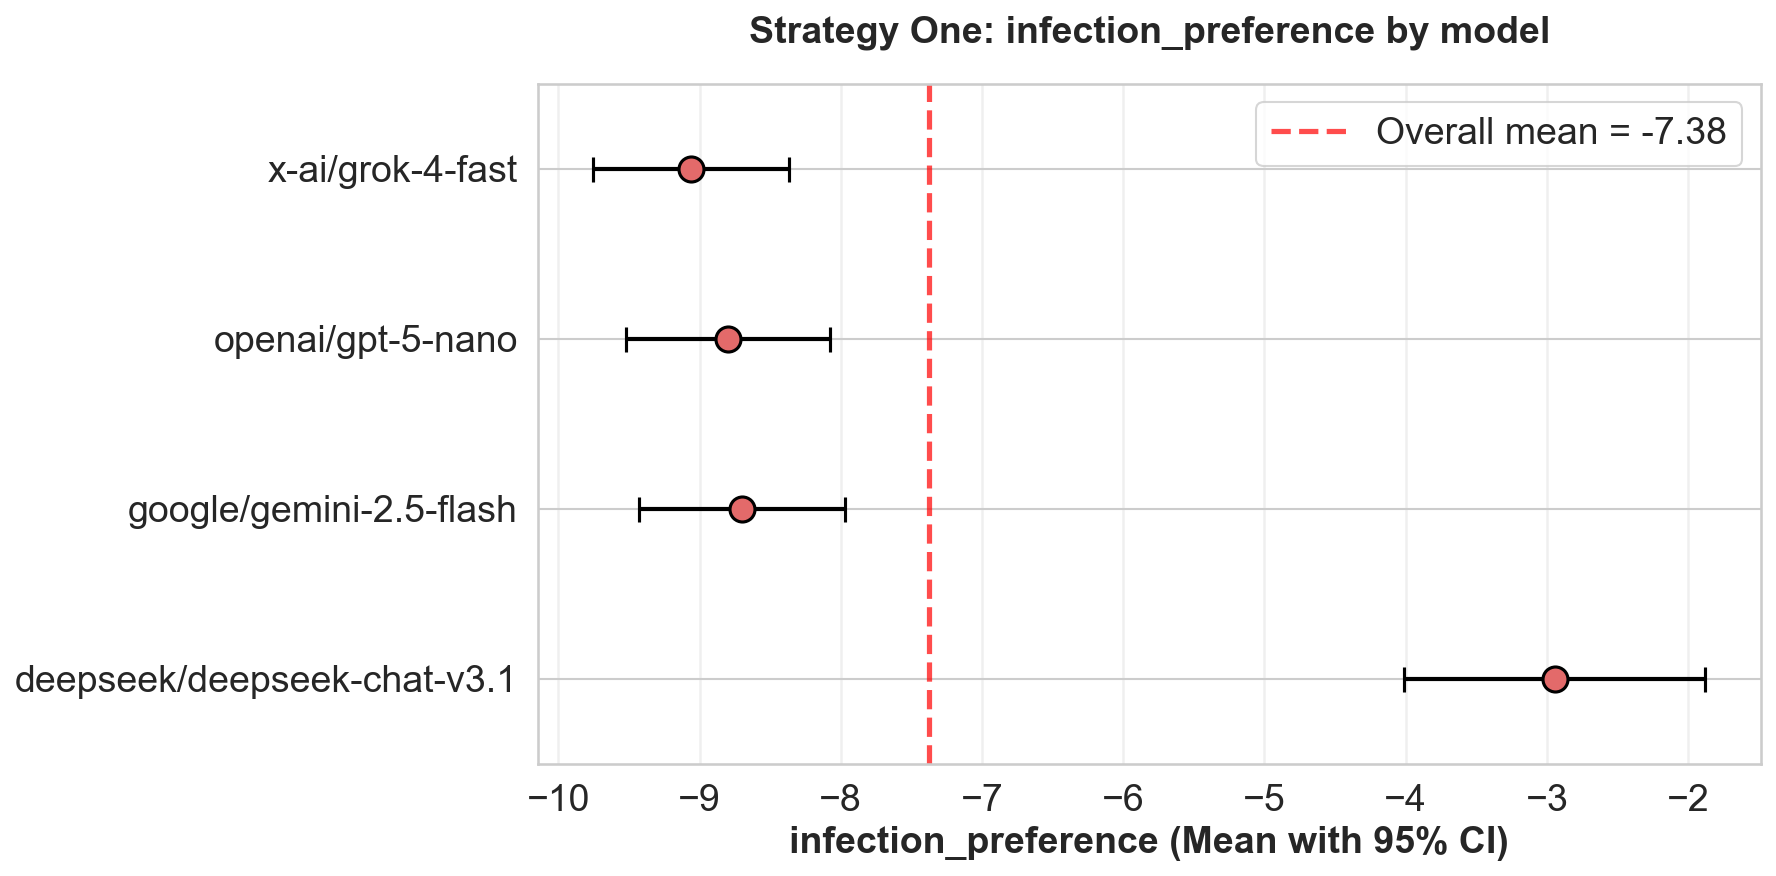

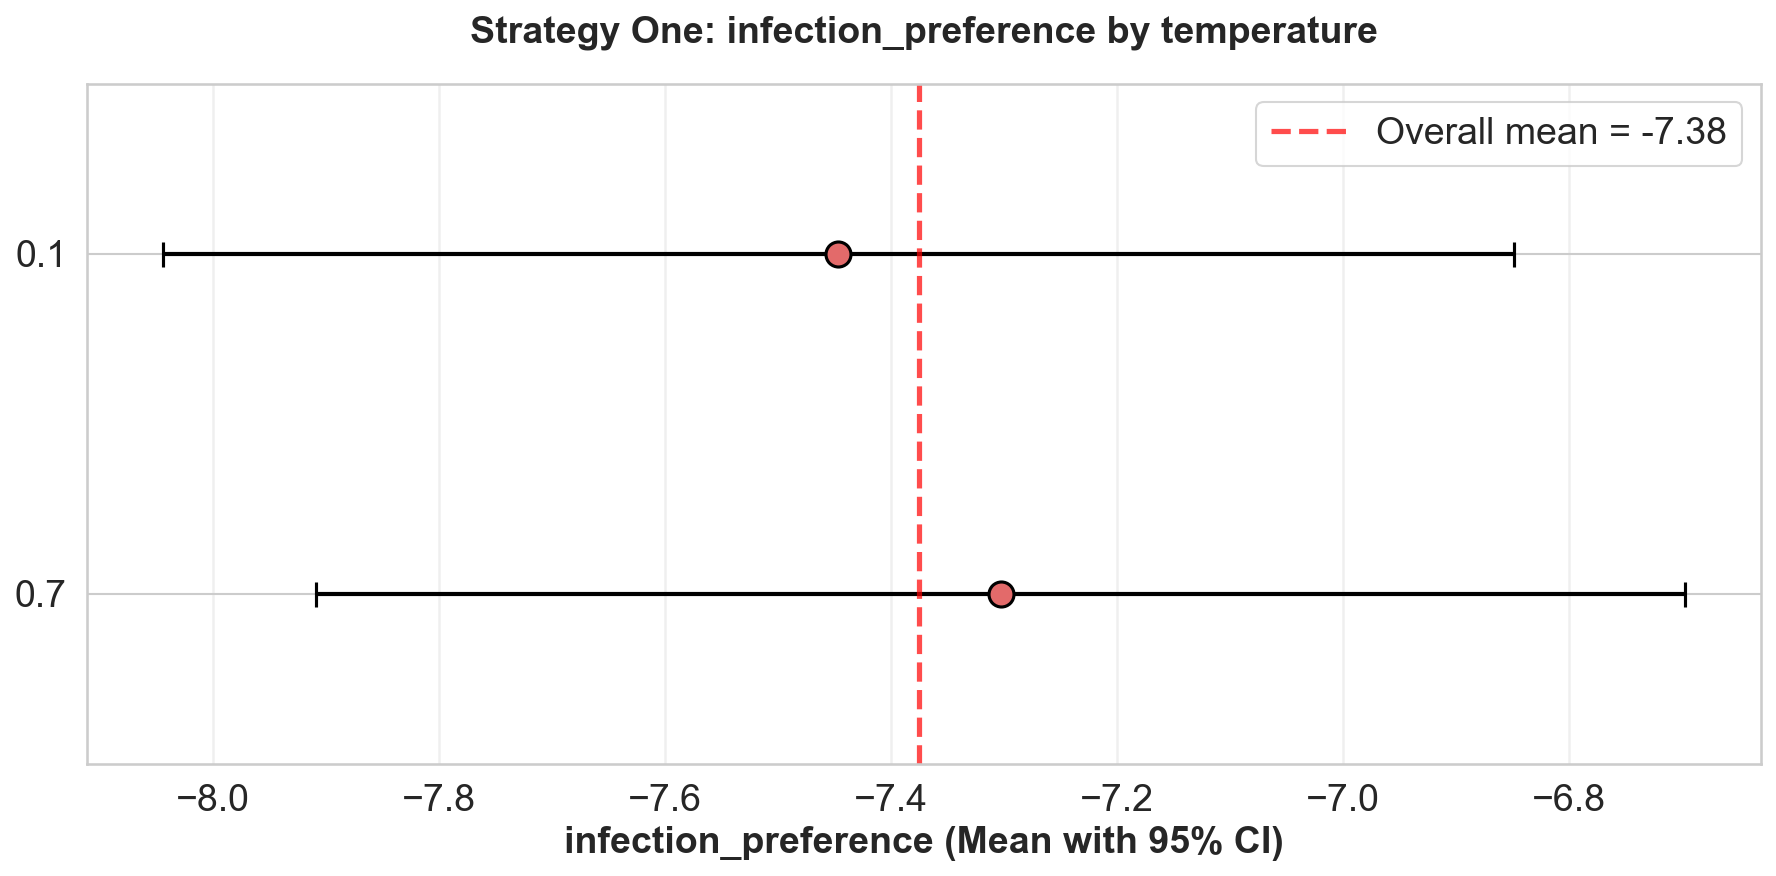

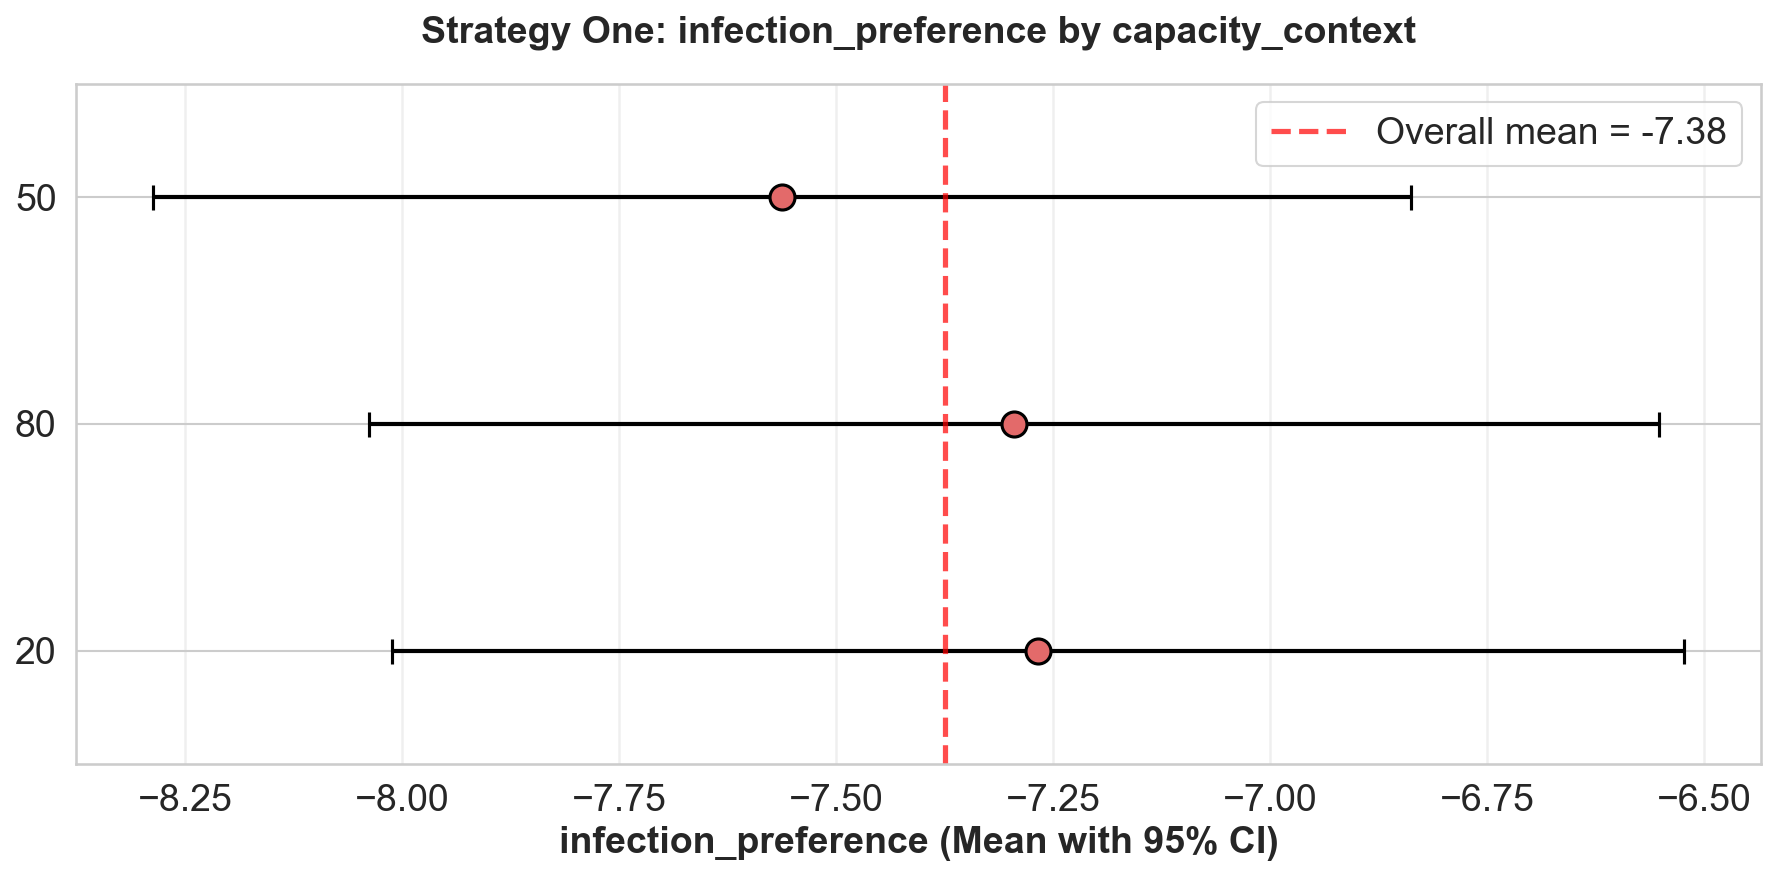


Labels wrapped at 30 characters per line
Overall mean infection_preference: -7.38


In [55]:
generate_errorbar_plot('infection_preference', df=df, context_cols=['model', 'temperature', 'capacity_context'], use_percentage=False)

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap
from scipy import stats
import pandas as pd
import numpy as np

def generate_errorbar_plot(response_col, df, context_cols=None, use_percentage=False,):

    # =========================
    # CONFIGURATION PARAMETERS
    # =========================
    MAX_LABEL_LENGTH = 30      # Characters per line for wrapped labels
    FIG_WIDTH = 12             # Figure width
    BASE_FIG_HEIGHT = 6        # Minimum figure height
    HEIGHT_PER_GROUP = 0.8     # Extra height per primary group

    MARKER_SIZE_SINGLE = 12    # Marker size for single-context plots
    MARKER_SIZE_MULTI = 10     # Marker size for multi-context plots
    MARKER_EDGE_WIDTH = 1.5
    ERROR_LINE_WIDTH = 2.0
    ERROR_CAP_SIZE = 6
    ERROR_CAP_THICK = 2

    # Spacing for grouped layout (multi-context)
    GROUP_SPACING = 1.0        # Distance between primary groups (y-axis)
    GROUP_BAR_HEIGHT = 0.7     # Total height occupied by all bars within a group

    # Font sizes
    TITLE_FONTSIZE = 18
    LABEL_FONTSIZE = 18
    TICK_FONTSIZE_X = 16
    TICK_FONTSIZE_Y = 16
    LEGEND_FONTSIZE = 14
    LEGEND_TITLE_FONTSIZE = 16

    # =========================
    # PLOTTING STYLE
    # =========================
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 300
    sns.set_theme(style='whitegrid')

    if context_cols is None:
        context_cols = ['model']

    unit = '%' if use_percentage else ''

    overall_mean = df[response_col].mean()
    if use_percentage:
        overall_mean = overall_mean * 100

    def wrap_label(text, max_len=MAX_LABEL_LENGTH):
        text = str(text)
        return '\n'.join(textwrap.wrap(text, width=max_len))

    # =======================================================
    # CASE 1: Single context column (original behavior)
    # =======================================================
    if len(context_cols) == 1:
        col = context_cols[0]
        grouped = df.groupby(col)[response_col]

        means = []
        ci_lower = []
        ci_upper = []
        labels = []

        for name, group in grouped:
            if len(group) > 0:
                data = group.values
                if use_percentage:
                    data = data * 100

                mean_val = data.mean()

                ci = stats.t.interval(
                    0.95,
                    len(data) - 1,
                    loc=mean_val,
                    scale=stats.sem(data)
                )

                means.append(mean_val)
                ci_lower.append(mean_val - ci[0])
                ci_upper.append(ci[1] - mean_val)
                labels.append(wrap_label(str(name)))

        sorted_indices = sorted(range(len(means)),
                                key=lambda i: means[i],
                                reverse=True)
        means = [means[i] for i in sorted_indices]
        ci_lower = [ci_lower[i] for i in sorted_indices]
        ci_upper = [ci_upper[i] for i in sorted_indices]
        labels = [labels[i] for i in sorted_indices]

        fig_height = max(BASE_FIG_HEIGHT, len(labels) * HEIGHT_PER_GROUP)
        fig, ax = plt.subplots(figsize=(FIG_WIDTH, fig_height))

        y_positions = range(1, len(labels) + 1)
        ax.errorbar(
            means,
            y_positions,
            xerr=[ci_lower, ci_upper],
            fmt='o',
            markersize=MARKER_SIZE_SINGLE,
            markerfacecolor='#e36a6a',
            markeredgecolor='black',
            markeredgewidth=MARKER_EDGE_WIDTH,
            ecolor='black',
            elinewidth=ERROR_LINE_WIDTH,
            capsize=ERROR_CAP_SIZE,
            capthick=ERROR_CAP_THICK,
            label=col,  # label for legend if desired
        )

        ax.axvline(
            overall_mean,
            color='red',
            linestyle='--',
            linewidth=2.5,
            alpha=0.7,
            label=f'Overall mean = {overall_mean:.2f}{unit}'
        )

        ax.set_yticks(list(y_positions))
        ax.set_yticklabels(labels, fontsize=TICK_FONTSIZE_Y)

        xlabel = f'{response_col} (Mean with 95% CI)'
        if use_percentage:
            xlabel = f'{response_col} (% Mean with 95% CI)'
        ax.set_xlabel(xlabel, fontsize=LABEL_FONTSIZE, fontweight='bold')
        ax.set_title(
            f'Strategy One: {response_col} by {col}',
            fontsize=TITLE_FONTSIZE,
            fontweight='bold',
            pad=20
        )

        ax.grid(True, axis='x', alpha=0.3, linewidth=1.2)
        ax.set_axisbelow(True)

        ax.legend(fontsize=LEGEND_FONTSIZE, loc='best')

        ax.tick_params(axis='x', labelsize=TICK_FONTSIZE_X)
        ax.tick_params(axis='y', labelsize=TICK_FONTSIZE_Y)

        ax.set_ylim(0.5, len(labels) + 0.5)

        plt.tight_layout()
        plt.show()

    # =======================================================
    # CASE 2: Multiple context columns (grouped bars)
    # =======================================================
    else:
        grouped = df.groupby(context_cols)[response_col]

        plot_data = []
        for name, group in grouped:
            if len(group) > 0:
                data = group.values
                if use_percentage:
                    data = data * 100

                mean_val = data.mean()
                ci = stats.t.interval(
                    0.95,
                    len(data) - 1,
                    loc=mean_val,
                    scale=stats.sem(data)
                )

                record = {}
                if isinstance(name, tuple):
                    for i, col in enumerate(context_cols):
                        record[col] = name[i]
                else:
                    record[context_cols[0]] = name

                record['mean'] = mean_val
                record['ci_lower'] = mean_val - ci[0]
                record['ci_upper'] = ci[1] - mean_val
                record['n'] = len(data)

                plot_data.append(record)

        plot_df = pd.DataFrame(plot_data)

        primary_col = context_cols[0]
        secondary_col = context_cols[1]

        primary_values = sorted(
            plot_df[primary_col].unique(),
            key=lambda x: plot_df[plot_df[primary_col] == x]['mean'].mean(),
            reverse=True
        )
        secondary_values = sorted(plot_df[secondary_col].unique())

        colors = sns.color_palette("husl", len(secondary_values))

        fig_height = max(BASE_FIG_HEIGHT, len(primary_values) * HEIGHT_PER_GROUP)
        fig, ax = plt.subplots(figsize=(FIG_WIDTH, fig_height))

        bar_height = GROUP_BAR_HEIGHT
        group_spacing = GROUP_SPACING
        bar_spacing = bar_height / max(1, len(secondary_values))

        y_positions = {}
        current_y = 1.0
        for primary_val in primary_values:
            y_positions[primary_val] = current_y
            current_y += group_spacing

        for i, secondary_val in enumerate(secondary_values):
            subset = plot_df[plot_df[secondary_col] == secondary_val]

            y_coords = []
            means = []
            ci_lowers = []
            ci_uppers = []

            for primary_val in primary_values:
                row = subset[subset[primary_col] == primary_val]
                if len(row) > 0:
                    y_offset = (i - len(secondary_values) / 2 + 0.5) * bar_spacing
                    y_coords.append(y_positions[primary_val] + y_offset)
                    means.append(row['mean'].values[0])
                    ci_lowers.append(row['ci_lower'].values[0])
                    ci_uppers.append(row['ci_upper'].values[0])

            ax.errorbar(
                means,
                y_coords,
                xerr=[ci_lowers, ci_uppers],
                fmt='o',
                markersize=MARKER_SIZE_MULTI,
                markerfacecolor=colors[i],
                markeredgecolor='black',
                markeredgewidth=MARKER_EDGE_WIDTH,
                ecolor='black',
                elinewidth=ERROR_LINE_WIDTH,
                capsize=ERROR_CAP_SIZE,
                capthick=ERROR_CAP_THICK,
                label=str(secondary_val),  # legend entry
            )

        ax.axvline(
            overall_mean,
            color='red',
            linestyle='--',
            linewidth=2.5,
            alpha=0.7,
            label=f'Overall mean = {overall_mean:.2f}{unit}',
            zorder=0,
        )

        wrapped_labels = [wrap_label(str(val)) for val in primary_values]
        ax.set_yticks([y_positions[val] for val in primary_values])
        ax.set_yticklabels(wrapped_labels, fontsize=TICK_FONTSIZE_Y)

        xlabel = f'{response_col} (Mean with 95% CI)'
        if use_percentage:
            xlabel = f'{response_col} (% Mean with 95% CI)'
        ax.set_xlabel(xlabel, fontsize=LABEL_FONTSIZE, fontweight='bold')

        title = f'Strategy Two: {response_col} by {primary_col} and {secondary_col}'
        ax.set_title(title, fontsize=TITLE_FONTSIZE, fontweight='bold', pad=20)

        ax.grid(True, axis='x', alpha=0.3, linewidth=1.2)
        ax.set_axisbelow(True)

        # Explicit key/legend for different groups
        ax.legend(
            fontsize=LEGEND_FONTSIZE,
            title=secondary_col,
            title_fontsize=LEGEND_TITLE_FONTSIZE,
            loc='best'
        )

        ax.tick_params(axis='x', labelsize=TICK_FONTSIZE_X)
        ax.tick_params(axis='y', labelsize=TICK_FONTSIZE_Y)

        ax.set_ylim(0.5, current_y - group_spacing + 0.5)

        plt.tight_layout()
        plt.show()

    print(f"\nLabels wrapped at {MAX_LABEL_LENGTH} characters per line")
    print(f"Overall mean {response_col}: {overall_mean:.2f}{unit}")
    print(f"Context columns: {', '.join(context_cols)}")


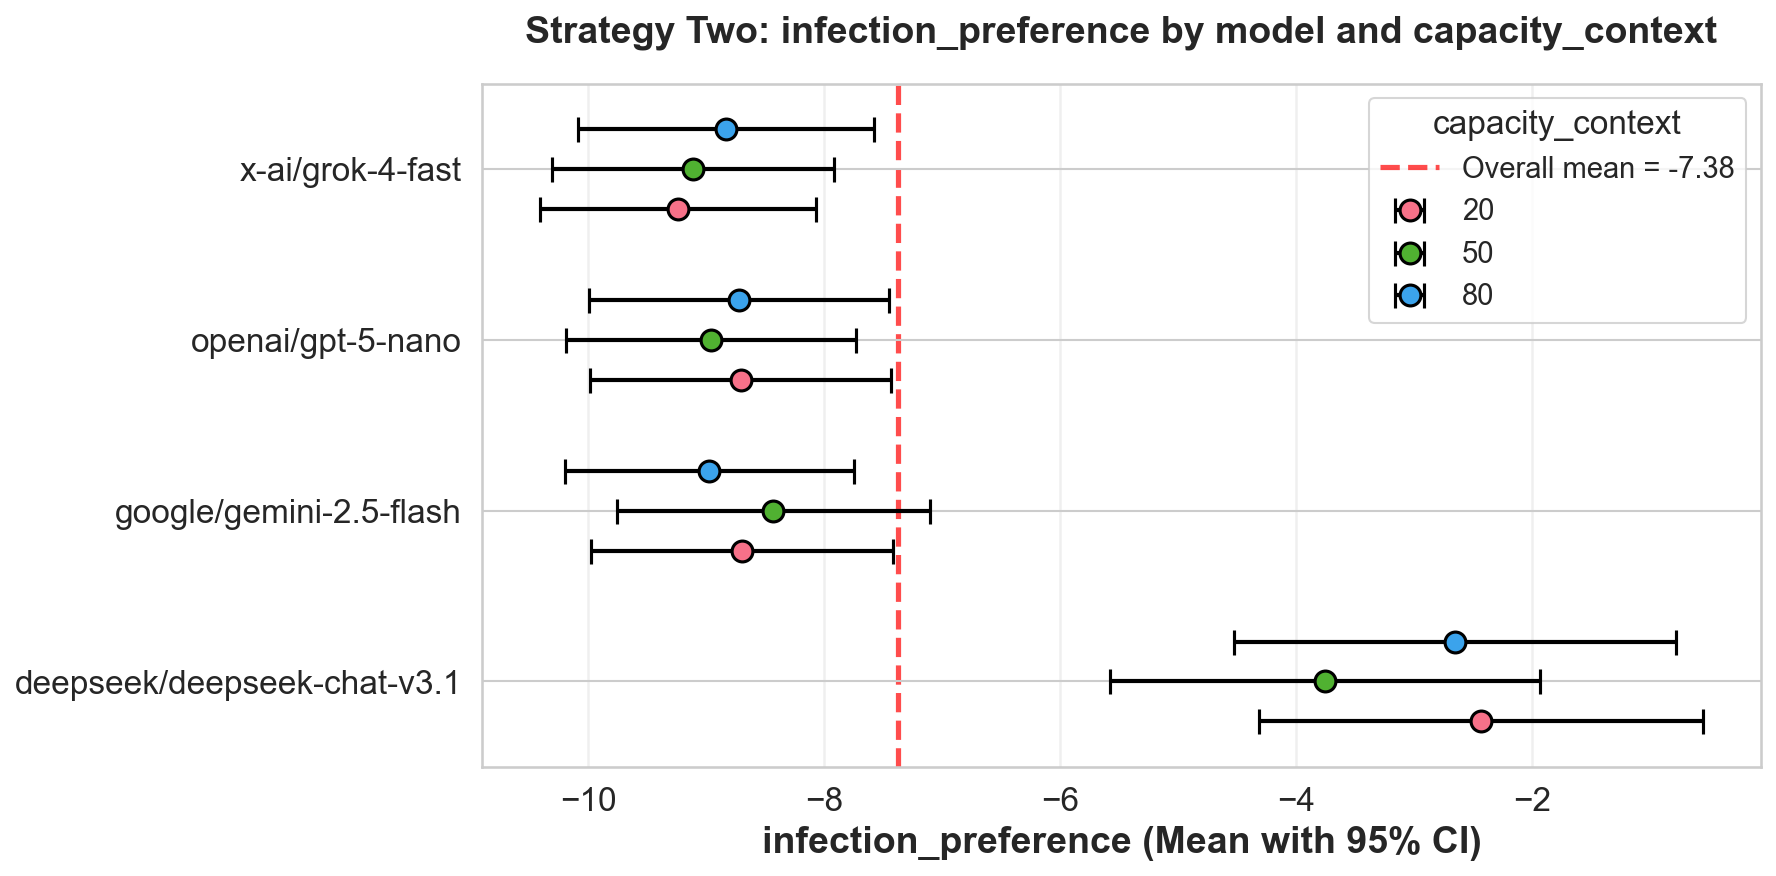


Labels wrapped at 30 characters per line
Overall mean infection_preference: -7.38
Context columns: model, capacity_context


In [57]:
generate_errorbar_plot('infection_preference', df=df, context_cols=['model', 'capacity_context'], use_percentage=False)

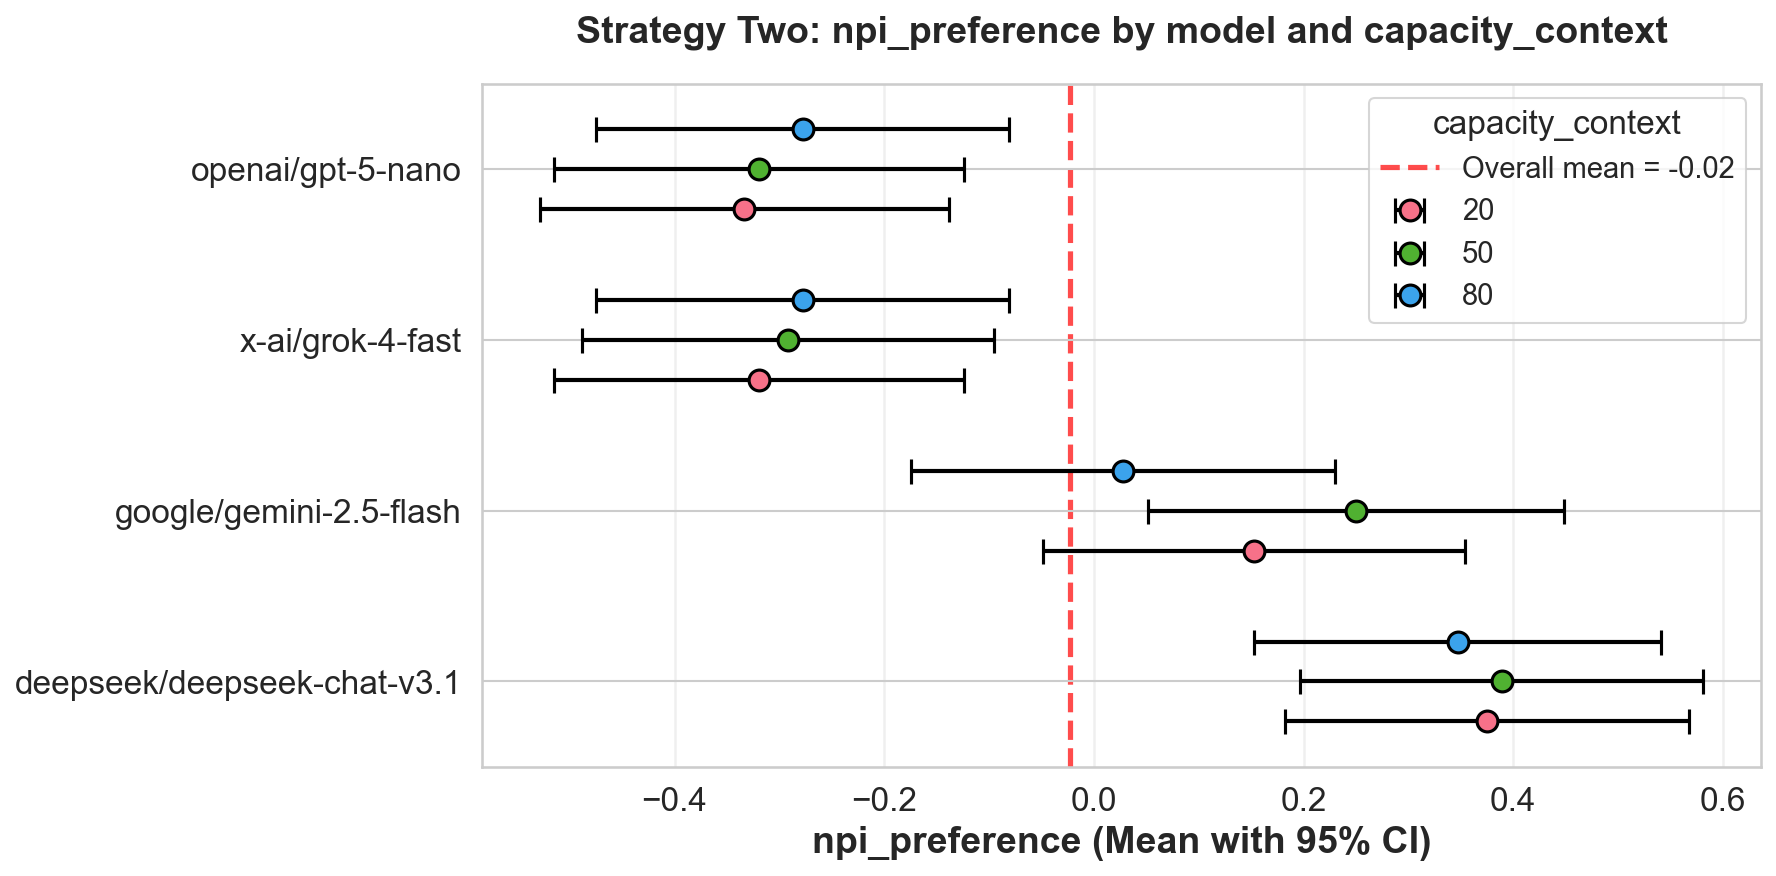


Labels wrapped at 30 characters per line
Overall mean npi_preference: -0.02
Context columns: model, capacity_context


In [58]:
generate_errorbar_plot('npi_preference', df=df, context_cols=['model', 'capacity_context'], use_percentage=False)

In [59]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_bad_choice_by_group(df, group_col, figsize=(12, 7)):
    """
    Simple bar plot showing proportion of bad choices by a single grouping variable.
    Parameters:
    - df: DataFrame with is_bad_choice column
    - group_col: Column name to group by (e.g., 'model', 'demographic')
    """
    # Set publication-quality settings
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 300
    
    # Set clean style
    sns.set_theme(style='whitegrid')
    
    # Calculate proportions
    bad_choice_rate = df.groupby(group_col)['is_bad_choice'].mean().reset_index()
    bad_choice_rate['bad_choice_pct'] = bad_choice_rate['is_bad_choice'] * 100
    
    # Sort by bad choice rate for better visualization
    bad_choice_rate = bad_choice_rate.sort_values('bad_choice_pct', ascending=False)
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create bar plot with better color palette
    sns.barplot(data=bad_choice_rate, 
                x=group_col, 
                y='bad_choice_pct', 
                palette='rocket',  # More distinct colors
                ax=ax,
                edgecolor='black',  # Add borders to bars
                linewidth=1.5)
    
    # Add value labels on top of bars (NOT bold)
    for i, bar in enumerate(ax.patches):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%',
                ha='center', va='bottom', fontsize=18)
    
    # Labels with better formatting
    ax.set_ylabel('Irrational Choice Rate (%)', fontweight='bold', fontsize=18)
    ax.set_xlabel(group_col.replace('_', ' ').title(), fontweight='bold', fontsize=18)
    ax.set_title(f'Strategy One: Irrational Choice Frequency by {group_col.replace("_", " ").title()}', 
                 fontweight='bold', pad=20, fontsize=18)
    
    # Rotate x-axis labels for better readability and set fontsize
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=18)
    ax.tick_params(axis='y', labelsize=18)
    
    # Grid for easier reading
    ax.grid(True, axis='y', alpha=0.3, linewidth=1.2)
    ax.set_axisbelow(True)
    
    # Add horizontal line at mean
    overall_mean = df['is_bad_choice'].mean() * 100
    ax.axhline(overall_mean, color='red', linestyle='--', linewidth=2.5, 
               alpha=0.7, label=f'Overall mean = {overall_mean:.1f}%')
    ax.legend(fontsize=18, loc='best')
    
    # Set y-axis to start at 0
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)  # Add 10% padding at top for labels
    
    plt.tight_layout()
    plt.show()

/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_95790/3208976526.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bad_choice_rate,
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_95790/3208976526.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=18)


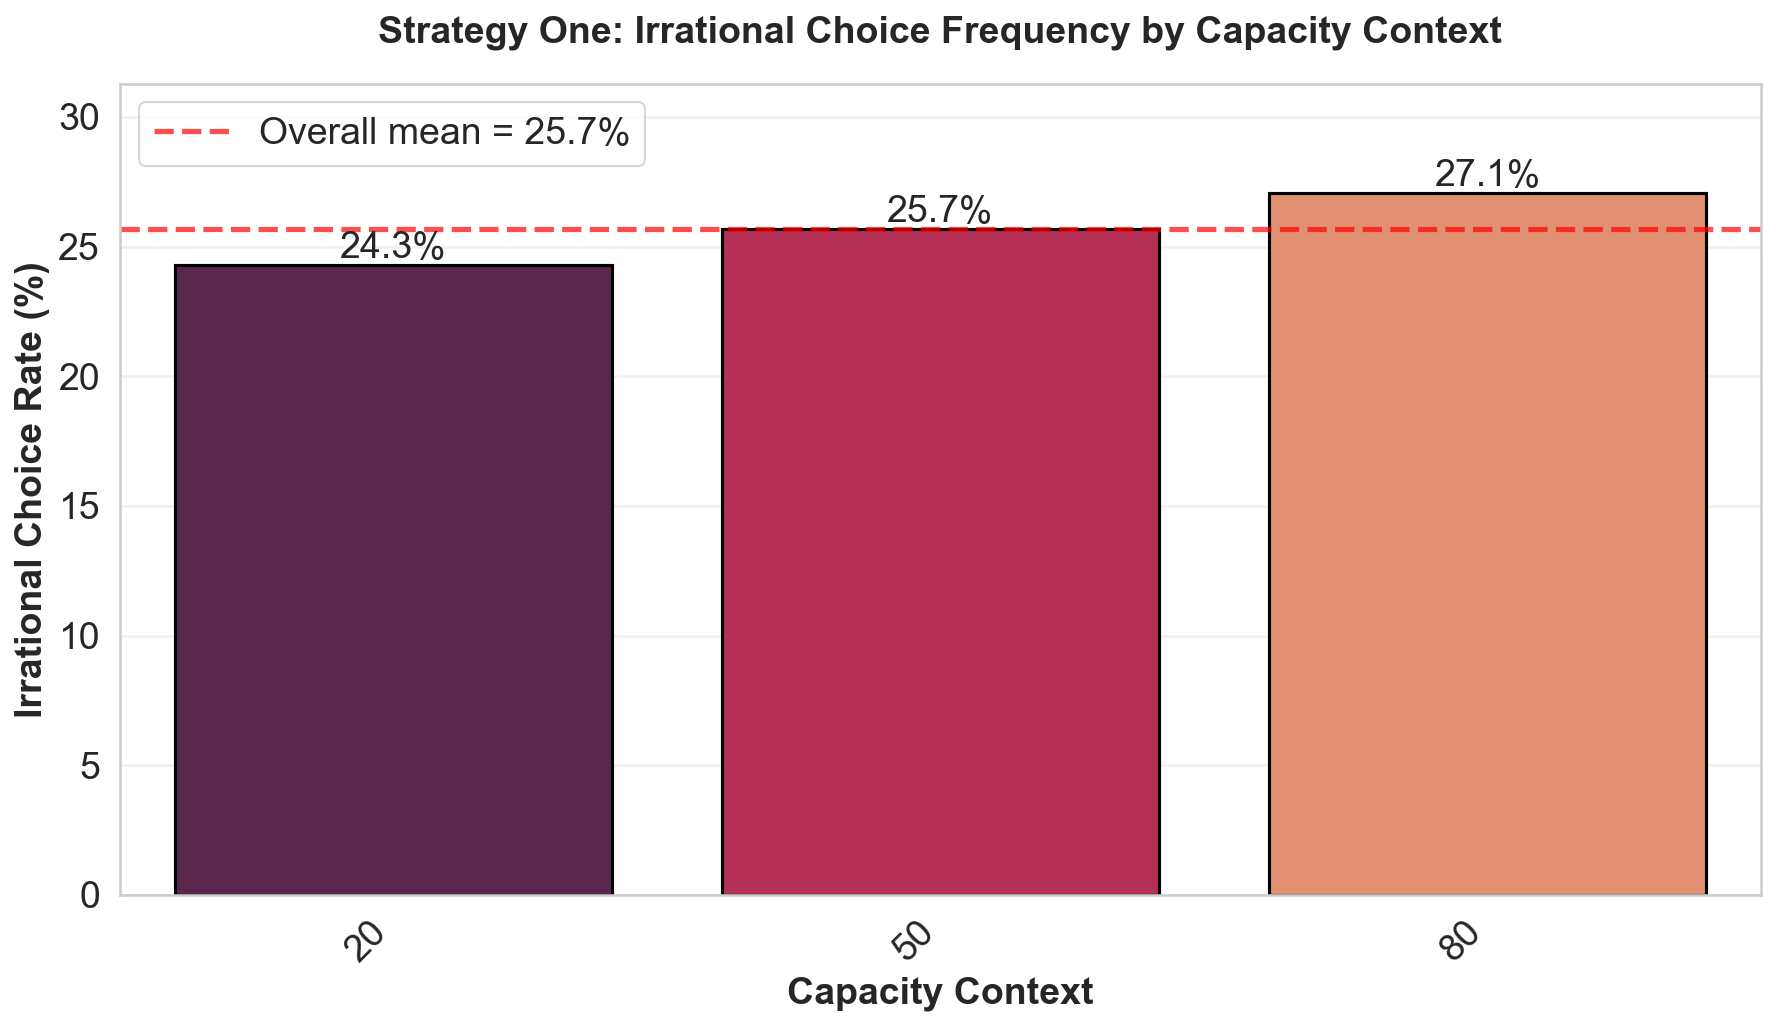

In [60]:
select_df = df[df['model'].str.lower().str.contains('gpt')]

# Example 1: Compare bad choice rates across models
plot_bad_choice_by_group(select_df, 'capacity_context')


In [61]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


def plot_bad_choice_by_group(df, group_col, hue_col=None, figsize=(18, 10)):
    """
    Publication-quality bar plot showing proportion of bad choices by a grouping variable,
    optionally with subgroups shown by color (hue).
    
    Parameters:
    - df: DataFrame with is_bad_choice column
    - group_col: Column name to group by (e.g., 'model', 'temperature')
    - hue_col: Optional column for subgrouping/coloring (e.g., 'capacity_context', 'economic_context')
    - figsize: Figure size (width, height) - larger for publication quality
    """
    # Set publication-quality settings
    plt.rcParams['figure.dpi'] = 300
    plt.rcParams['savefig.dpi'] = 600
    plt.rcParams['font.family'] = 'serif'
    plt.rcParams['font.size'] = 14
    
    # Set clean style with appropriate context
    sns.set_theme(style='whitegrid')
    sns.set_context("paper", font_scale=1.8)
    
    # Calculate proportions
    if hue_col:
        # Grouped calculation with subgroups
        bad_choice_rate = df.groupby([group_col, hue_col])['is_bad_choice'].mean().reset_index()
        bad_choice_rate['bad_choice_pct'] = bad_choice_rate['is_bad_choice'] * 100
        
        # Sort primary groups by overall bad choice rate
        group_order = df.groupby(group_col)['is_bad_choice'].mean().sort_values(ascending=False).index
        
        # Adjust figure width based on number of groups and subgroups
        n_groups = len(group_order)
        n_hues = df[hue_col].nunique()
        # More generous spacing for grouped bars
        figsize = (max(18, n_groups * 3.5), 10)
    else:
        # Simple calculation without subgroups
        bad_choice_rate = df.groupby(group_col)['is_bad_choice'].mean().reset_index()
        bad_choice_rate['bad_choice_pct'] = bad_choice_rate['is_bad_choice'] * 100
        
        # Sort by bad choice rate
        bad_choice_rate = bad_choice_rate.sort_values('bad_choice_pct', ascending=False)
        group_order = bad_choice_rate[group_col].values
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create bar plot with optional hue
    if hue_col:
        # Wider bars and better spacing for grouped bars
        plot = sns.barplot(data=bad_choice_rate, 
                          x=group_col, 
                          y='bad_choice_pct', 
                          hue=hue_col,
                          order=group_order,
                          palette='Set2',
                          ax=ax,
                          edgecolor='black',
                          linewidth=1.8,
                          errorbar=None,
                          width=0.85,  # Wider bars to accommodate labels
                          gap=0.15)  # Increased gap between groups
        
        # Add value labels with better positioning to prevent overlap
        for i, container in enumerate(ax.containers):
            labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
            
            # Alternate label positions to reduce overlap
            # Labels for first half go on top, second half slightly offset
            if i < len(ax.containers) / 2:
                ax.bar_label(container, 
                            labels=labels,
                            fontsize=15,
                            padding=10,  # More padding
                            weight='normal')
            else:
                ax.bar_label(container, 
                            labels=labels,
                            fontsize=15,
                            padding=10,
                            weight='normal')
        
    else:
        plot = sns.barplot(data=bad_choice_rate, 
                          x=group_col, 
                          y='bad_choice_pct', 
                          palette='rocket',
                          ax=ax,
                          edgecolor='black',
                          linewidth=2.0,
                          width=0.7)
        
        # Add value labels on top of bars
        for i, bar in enumerate(ax.patches):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 1.5,
                    f'{height:.1f}%',
                    ha='center', va='bottom', fontsize=18, weight='normal')
    
    # Labels with publication-quality formatting
    ax.set_ylabel('Irrational Choice Rate (%)', fontweight='bold', fontsize=22)
    ax.set_xlabel(group_col.replace('_', ' ').title(), fontweight='bold', fontsize=22)
    
    # Title with optional hue mention
    if hue_col:
        title = f'Irrational Choice Frequency by {group_col.replace("_", " ").title()} and {hue_col.replace("_", " ").title()}'
    else:
        title = f'Irrational Choice Frequency by {group_col.replace("_", " ").title()}'
    ax.set_title(title, fontweight='bold', pad=25, fontsize=24)
    
    # Rotate x-axis labels for better readability
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=20)
    ax.tick_params(axis='y', labelsize=20)
    ax.tick_params(axis='both', width=1.5, length=6)
    
    # Grid for easier reading
    ax.grid(True, axis='y', alpha=0.3, linewidth=1.2, linestyle='-', zorder=0)
    ax.set_axisbelow(True)
    
    # Thicker spine for publication quality
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
    
    # Add horizontal line at mean
    overall_mean = df['is_bad_choice'].mean() * 100
    ax.axhline(overall_mean, color='#d62728', linestyle='--', linewidth=2.5, 
               alpha=0.85, label=f'Overall mean = {overall_mean:.1f}%', zorder=3)
    
    # Format legend for publication
    if hue_col:
        legend = ax.legend(title=hue_col.replace('_', ' ').title(), 
                          fontsize=18, 
                          title_fontsize=20,
                          loc='upper left', 
                          bbox_to_anchor=(1.02, 1),
                          frameon=True,
                          fancybox=True,
                          shadow=True,
                          framealpha=0.98,
                          edgecolor='black')
        legend.get_frame().set_linewidth(1.5)
    else:
        ax.legend(fontsize=18, loc='best', frameon=True, shadow=True, 
                 edgecolor='black', framealpha=0.98)
    
    # Set y-axis limits with MORE space for labels to prevent overlap
    y_max = bad_choice_rate['bad_choice_pct'].max()
    ax.set_ylim(0, y_max * 1.35)  # 35% padding at top for labels
    
    # Add margins on x-axis to give space around outer bars
    ax.margins(x=0.02)
    
    # Format y-axis
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}'))
    
    # Tighten layout to prevent label cutoff
    plt.tight_layout()
    
    return fig, ax


# Function to save figure in publication-ready formats
def save_publication_figure(fig, filename, formats=['png', 'pdf', 'svg']):
    """
    Save figure in multiple publication-ready formats.
    
    Parameters:
    - fig: matplotlib figure object
    - filename: base filename without extension
    - formats: list of formats to save (default: png, pdf, svg)
    """
    for fmt in formats:
        fig.savefig(f'{filename}.{fmt}', 
                   dpi=600,
                   bbox_inches='tight',
                   facecolor='white',
                   edgecolor='none',
                   format=fmt)
        print(f"Saved: {filename}.{fmt}")


# Alternative version with conditional label display for very crowded plots
def plot_bad_choice_by_group_selective_labels(df, group_col, hue_col=None, 
                                               min_height_for_label=2.0, figsize=(18, 10)):
    """
    Same as above but only shows labels for bars above a certain height threshold.
    Useful for very crowded plots where many small bars exist.
    
    Parameters:
    - min_height_for_label: Minimum bar height (%) to show label (default: 2.0)
    """
    # [Same setup code as above...]
    # Then modify the bar_label section:
    
    # Only add labels to bars above threshold
    for container in ax.containers:
        labels = [f'{v:.1f}%' if v >= min_height_for_label else '' 
                 for v in container.datavalues]
        ax.bar_label(container, labels=labels, fontsize=15, padding=10)
    
    # [Rest of the code...]


# Example usage:

# Simple plot (no subgroups)
# fig, ax = plot_bad_choice_by_group(df, group_col='model')
# save_publication_figure(fig, 'figure1_model_comparison')

# Grouped plot with subgroups by capacity context
# fig, ax = plot_bad_choice_by_group(df, group_col='model', hue_col='capacity_context')
# save_publication_figure(fig, 'figure2_model_by_capacity')

# For very crowded plots, use selective labels
# fig, ax = plot_bad_choice_by_group_selective_labels(df, group_col='model', 
#                                                      hue_col='economic_context',
#                                                      min_height_for_label=3.0)


/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_95790/2410590450.py:117: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=20)


(<Figure size 5400x3000 with 1 Axes>,
 <Axes: title={'center': 'Irrational Choice Frequency by Model and Capacity Context'}, xlabel='Model', ylabel='Irrational Choice Rate (%)'>)

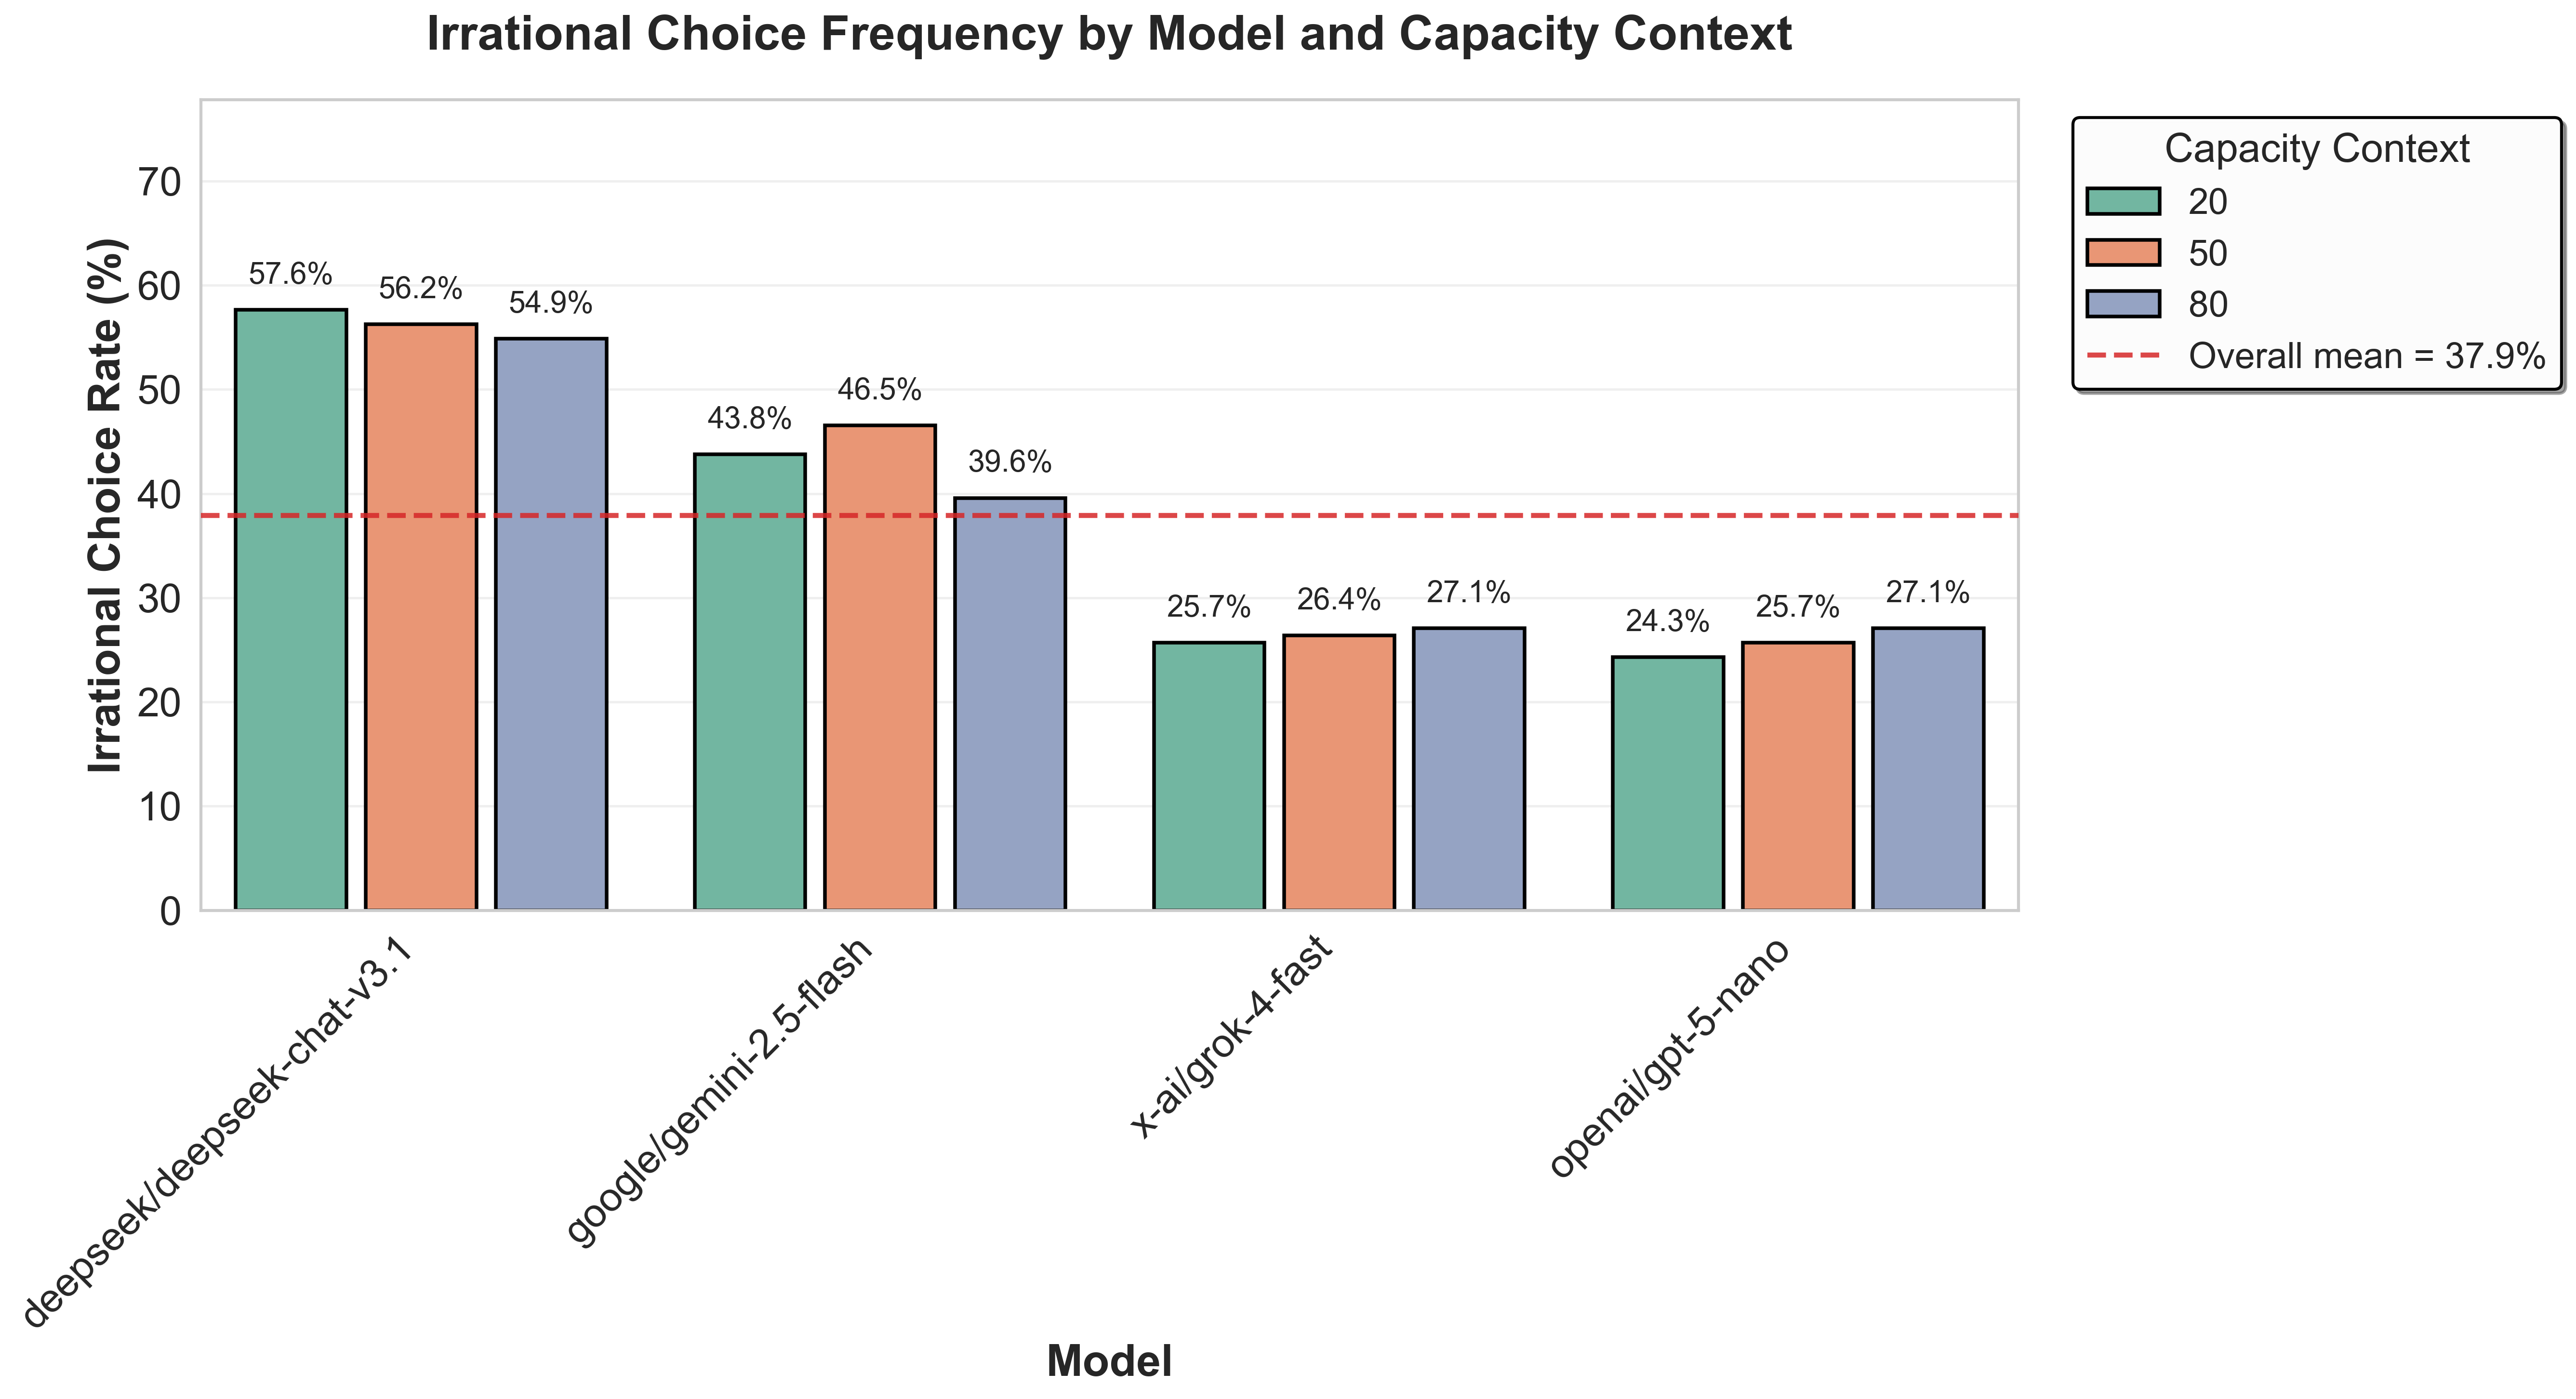

In [62]:
plot_bad_choice_by_group(df, group_col='model', hue_col='capacity_context')